# Class Quiz
### Guideline
1. Please submit the file via Google Classroom.
2. File name convention is MSA38DN_\<Your full name\>\_classquizN
3. Provide your personal information in the next block.

### Student information
Full name: Bùi Ngọc Bảo Trân

Student ID: 25MS33062

Group: 2

In [2]:
import os
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

import requests

# define your addition imported libraries below

In [3]:
file_id = '1zWdY9vyhKyYO1aLNumAwHNpQ9OeZWo-S'
# file_id = '1rIpbUYCX_aUHF4H_0vNPtyYAoTS3tUSj'
download_url = f'https://drive.google.com/uc?export=download&id={file_id}'
img_color = None

In [4]:
def download_video(download_url, no_frames=-1, print_info=False):
  '''
  Download video from the given url.

  Return a list of frames.
  '''

  frames = []

  try:
    # Download the video
    response = requests.get(download_url, stream=True)
    response.raise_for_status()  # Raise an exception for bad status codes

    # read the video from the downloaded bytes
    video = cv.VideoCapture(download_url)

    assert video.isOpened(), "Error opening video file."

    fps = video.get(cv.CAP_PROP_FPS)
    no_frames = int(video.get(cv.CAP_PROP_FRAME_COUNT)) if no_frames == -1 else no_frames
    while len(frames) <= no_frames:
      ret, frame = video.read()
      if not ret:
        break  # Exit the loop when all frames are read

      if cv.waitKey(int(1000/fps)) & 0xFF == ord('q'):
        break

      frames.append(frame)

    if print_info:
      width = int(video.get(cv.CAP_PROP_FRAME_WIDTH))
      height = int(video.get(cv.CAP_PROP_FRAME_HEIGHT))
      frame_count = int(video.get(cv.CAP_PROP_FRAME_COUNT))
      duration = frame_count / fps

      print(f"Frames per second: {fps}")
      print(f"Width: {width} pixels")
      print(f"Height: {height} pixels")
      print(f"Frame count: {frame_count}")
      print(f"Duration: {duration:.2f} seconds")

    video.release()
    cv.destroyAllWindows()
  except requests.exceptions.RequestException as e:
    print(f"Error downloading video: {e}")
  except Exception as e:
    print(f"An error occurred: {e}")

  return frames

In [6]:
frames = download_video(download_url, -1, True)
print(download_url)

Frames per second: 30.0
Width: 768 pixels
Height: 1152 pixels
Frame count: 153
Duration: 5.10 seconds
https://drive.google.com/uc?export=download&id=1zWdY9vyhKyYO1aLNumAwHNpQ9OeZWo-S


In [7]:
height, width, layers = frames[0].shape

out = cv.VideoWriter(
    "input_quiz7.mp4", 
    cv.VideoWriter_fourcc(*'mp4v'), 
    30.0, 
    (width, height)
)

for frame in frames:
    out.write(frame)

out.release()
print("Đã lưu input_quiz7.mp4")

Đã lưu input_quiz7.mp4


# Requirements
3. Perform edge detection on the given image by spatial and frequency approaches (one for each). Display the results.
4. Thicken the edges and remove trivial details from the output (3). Display the results.
5. Switch all yellow areas in the input image to blue.

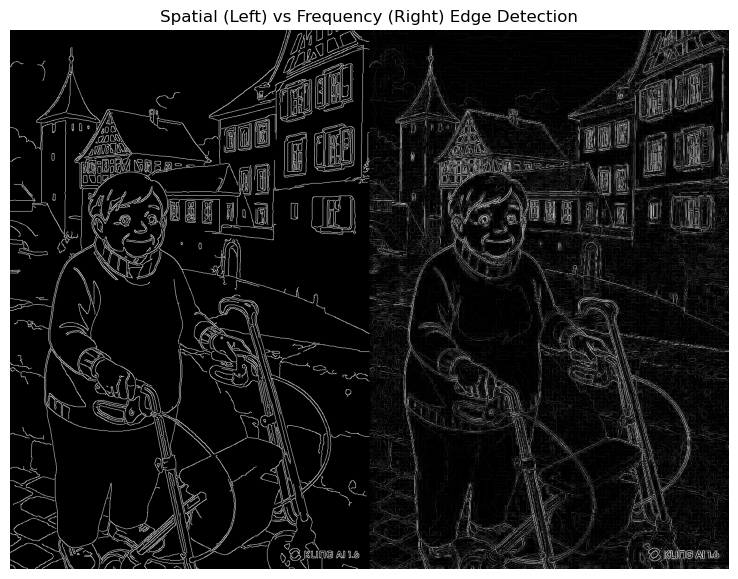

In [8]:
# 3. Perform edge detection on the given image by spatial and frequency approaches (one for each). Display the results.
from IPython.display import display, HTML

video_path = "input_quiz7.mp4"
q3_path = "25MS33062_Q3.mp4"

cap = cv.VideoCapture(video_path)
fps = cap.get(cv.CAP_PROP_FPS)
width = int(cap.get(cv.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv.CAP_PROP_FRAME_HEIGHT))

writer = cv.VideoWriter(
    q3_path, cv.VideoWriter_fourcc(*"xvid"), fps, (width * 2, height), True
)

sample_frames = []

while True:
    ret, frame = cap.read()
    if not ret:
        break

    gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)

    # 1. Spatial Edge Detection (Canny):
    blur = cv.GaussianBlur(gray, (5, 5), 0)
    spatial = cv.Canny(blur, 30, 100)

    # 2. Frequency Edge Detection (FFT High-pass + Laplacian):
    F = np.fft.fft2(gray)
    Fshift = np.fft.fftshift(F)
    rows, cols = gray.shape
    crow, ccol = rows // 2, cols // 2
    Y, X = np.ogrid[:rows, :cols]
    radius = 20
    mask = np.ones((rows, cols), np.float32)
    center = (Y - crow) ** 2 + (X - ccol) ** 2 <= radius**2
    mask[center] = 0
    Fshift_filtered = Fshift * mask
    freq = np.abs(np.fft.ifft2(np.fft.ifftshift(Fshift_filtered)))
    freq = cv.normalize(freq, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)
    freq_edge = cv.Laplacian(freq, cv.CV_8U, ksize=3)

    output = np.hstack(
        [
            cv.cvtColor(spatial, cv.COLOR_GRAY2BGR),
            cv.cvtColor(freq_edge, cv.COLOR_GRAY2BGR),
        ]
    )
    writer.write(output)

    if len(sample_frames) < 1:
        sample_frames.append(cv.cvtColor(output, cv.COLOR_BGR2RGB))

cap.release()
writer.release()

# Display results
if len(sample_frames) > 0:
    plt.figure(figsize=(15, 7))
    plt.imshow(sample_frames[0])
    plt.title("Spatial (Left) vs Frequency (Right) Edge Detection")
    plt.axis("off")
    plt.show()

display(
    HTML(f"""
<div>
    <p>Video xử lý đã hoàn tất: <b>{q3_path}</b></p>
    <a href="https://drive.google.com/file/d/1JQo3PJW-zlhNZzso6fX_J_KJ1jxpAP-8/view" 
        target="_blank">
        👉 Nhấn vào đây để xem video 25MS33062_Q3 đầy đủ trên Google Drive
    </a>
</div>
""")
)

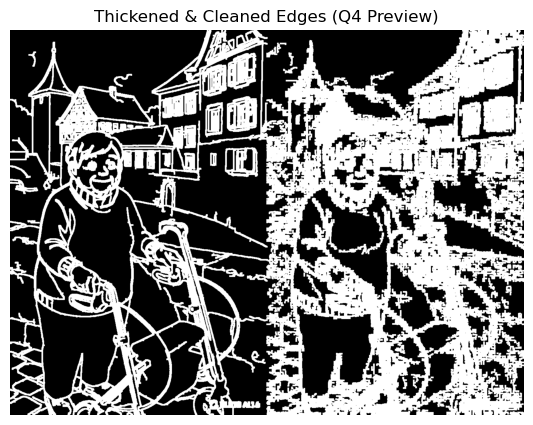

In [9]:
# 4. Thicken the edges and remove trivial details from the output (3). Display the results.
q3_path = "25MS33062_Q3.mp4"
q4_path = "25MS33062_Q4.mp4"

cap = cv.VideoCapture(q3_path)
fps = cap.get(cv.CAP_PROP_FPS)
width = int(cap.get(cv.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv.CAP_PROP_FRAME_HEIGHT))

writer = cv.VideoWriter(
    q4_path, cv.VideoWriter_fourcc(*"xvid"), fps, (width, height), True
)

kernel_close = np.ones((5, 5), np.uint8)
kernel_dilate = np.ones((3, 3), np.uint8)
kernel_open = np.ones((3, 3), np.uint8)

sample_frames = []

while True:
    ret, frame = cap.read()
    if not ret:
        break

    gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    _, binary = cv.threshold(gray, 30, 255, cv.THRESH_BINARY)
    closed = cv.morphologyEx(binary, cv.MORPH_CLOSE, kernel_close, iterations=1)
    thick = cv.dilate(closed, kernel_dilate, iterations=2)
    opened = cv.morphologyEx(thick, cv.MORPH_OPEN, kernel_open, iterations=1)
    num_labels, labels, stats, _ = cv.connectedComponentsWithStats(
        opened, connectivity=8
    )
    cleaned = np.zeros_like(opened)

    for i in range(1, num_labels):
        if stats[i, cv.CC_STAT_AREA] > 300:
            cleaned[labels == i] = 255

    cleaned_bgr = cv.cvtColor(cleaned, cv.COLOR_GRAY2BGR)
    writer.write(cleaned_bgr)

    if len(sample_frames) < 1:
        sample_frames.append(cv.cvtColor(cleaned_bgr, cv.COLOR_BGR2RGB))

cap.release()
writer.release()

# Display results
if len(sample_frames) > 0:
    plt.figure(figsize=(10, 5))
    plt.imshow(sample_frames[0])
    plt.title("Thickened & Cleaned Edges (Q4 Preview)")
    plt.axis("off")
    plt.show()

display(
    HTML(f"""
<div>
    <p>Video xử lý đã hoàn tất: <b>{q4_path}</b></p>
    <a href="https://drive.google.com/file/d/1zht4pOMv_hT_zfpANqnC9K1SgV3VQ5AB/view" 
        target="_blank">
        👉 Nhấn vào đây để xem video 25MS33062_Q4 đầy đủ trên Google Drive
    </a>
</div>
""")
)

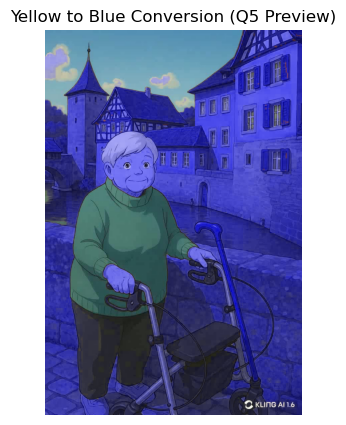

In [10]:
# 5. Switch all yellow areas in the input image to blue.
video_path = "input_quiz7.mp4"
q5_path = "25MS33062_Q5.mp4"

cap = cv.VideoCapture(video_path)
fps = cap.get(cv.CAP_PROP_FPS)
width = int(cap.get(cv.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv.CAP_PROP_FRAME_HEIGHT))

writer = cv.VideoWriter(
    q5_path, cv.VideoWriter_fourcc(*"xvid"), fps, (width, height), True
)

sample_frames = []

while True:
    ret, frame = cap.read()
    if not ret:
        break

    hsv = cv.cvtColor(frame, cv.COLOR_BGR2HSV).astype(np.float32)
    h, s, v = cv.split(hsv)
    lower_yellow = np.array([10, 40, 40])
    upper_yellow = np.array([45, 255, 255])

    mask = cv.inRange(frame, np.array([0, 100, 100]), np.array([100, 255, 255]))
    mask_blurred = (
        cv.GaussianBlur(
            cv.inRange(
                hsv.astype(np.uint8), np.array([10, 40, 40]), np.array([45, 255, 255])
            ),
            (7, 7),
            0,
        )
        / 255.0
    )
    mask_blurred = np.expand_dims(mask_blurred, axis=-1)

    h_new = h.copy()
    h_new[mask_blurred[:, :, 0] > 0.1] = 120
    hsv_new = cv.merge([h_new, s, v])
    img_blue = cv.cvtColor(hsv_new.astype(np.uint8), cv.COLOR_HSV2BGR)

    final_img = (img_blue * mask_blurred + frame * (1 - mask_blurred)).astype(np.uint8)
    writer.write(final_img)

    if len(sample_frames) < 1:
        sample_frames.append(cv.cvtColor(final_img, cv.COLOR_BGR2RGB))

cap.release()
writer.release()

# Display results
if len(sample_frames) > 0:
    plt.figure(figsize=(10, 5))
    plt.imshow(sample_frames[0])
    plt.title("Yellow to Blue Conversion (Q5 Preview)")
    plt.axis("off")
    plt.show()

display(
    HTML(f"""
<div>
    <p>Video xử lý đã hoàn tất: <b>{q5_path}</b></p>
    <a href="https://drive.google.com/file/d/1hcPMEzjhjigN3upLmL9BY_0uxx0Ld7xi/view" 
        target="_blank">
        👉 Nhấn vào đây để xem video 25MS33062_Q5 đầy đủ trên Google Drive
    </a>
</div>
""")
)